
A1 x = b1
исходная: T = -1.898515, tau = (-0.0000, 6.9307)
Tol_i(tau) = [-1.898515 -1.898515]
b: T' = 0.000000, tau' = (-0.0000, 6.9307)
A: T' = 0.000000, tau' = (-0.0000, 6.9307)
Ab: T' = 0.000000, tau' = (-0.0000, 6.9307)


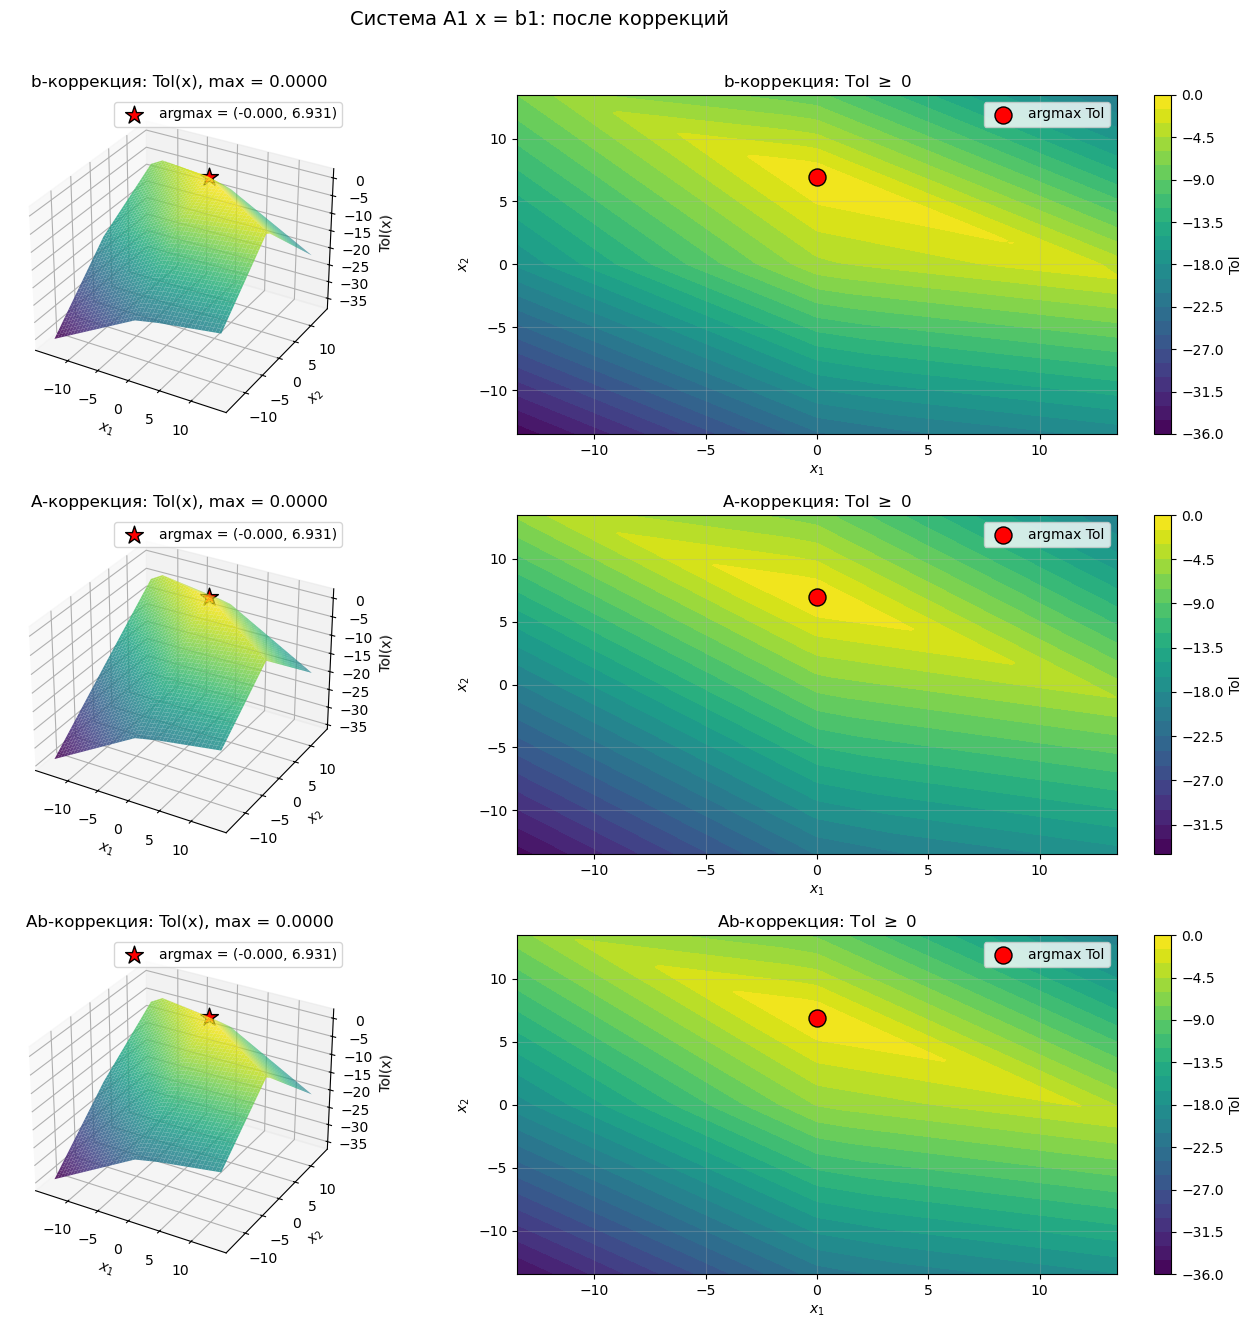


A2 x = b2
исходная: T = -2.183333, tau = (-0.0000, 7.1465)
Tol_i(tau) = [-2.140404 -2.183333 -2.183333]
b: T' = 0.000000, tau' = (-0.0000, 7.1465)
A: T' = 0.000000, tau' = (2.4464, 5.4241)
Ab: T' = 0.000000, tau' = (-0.0000, 7.1465)


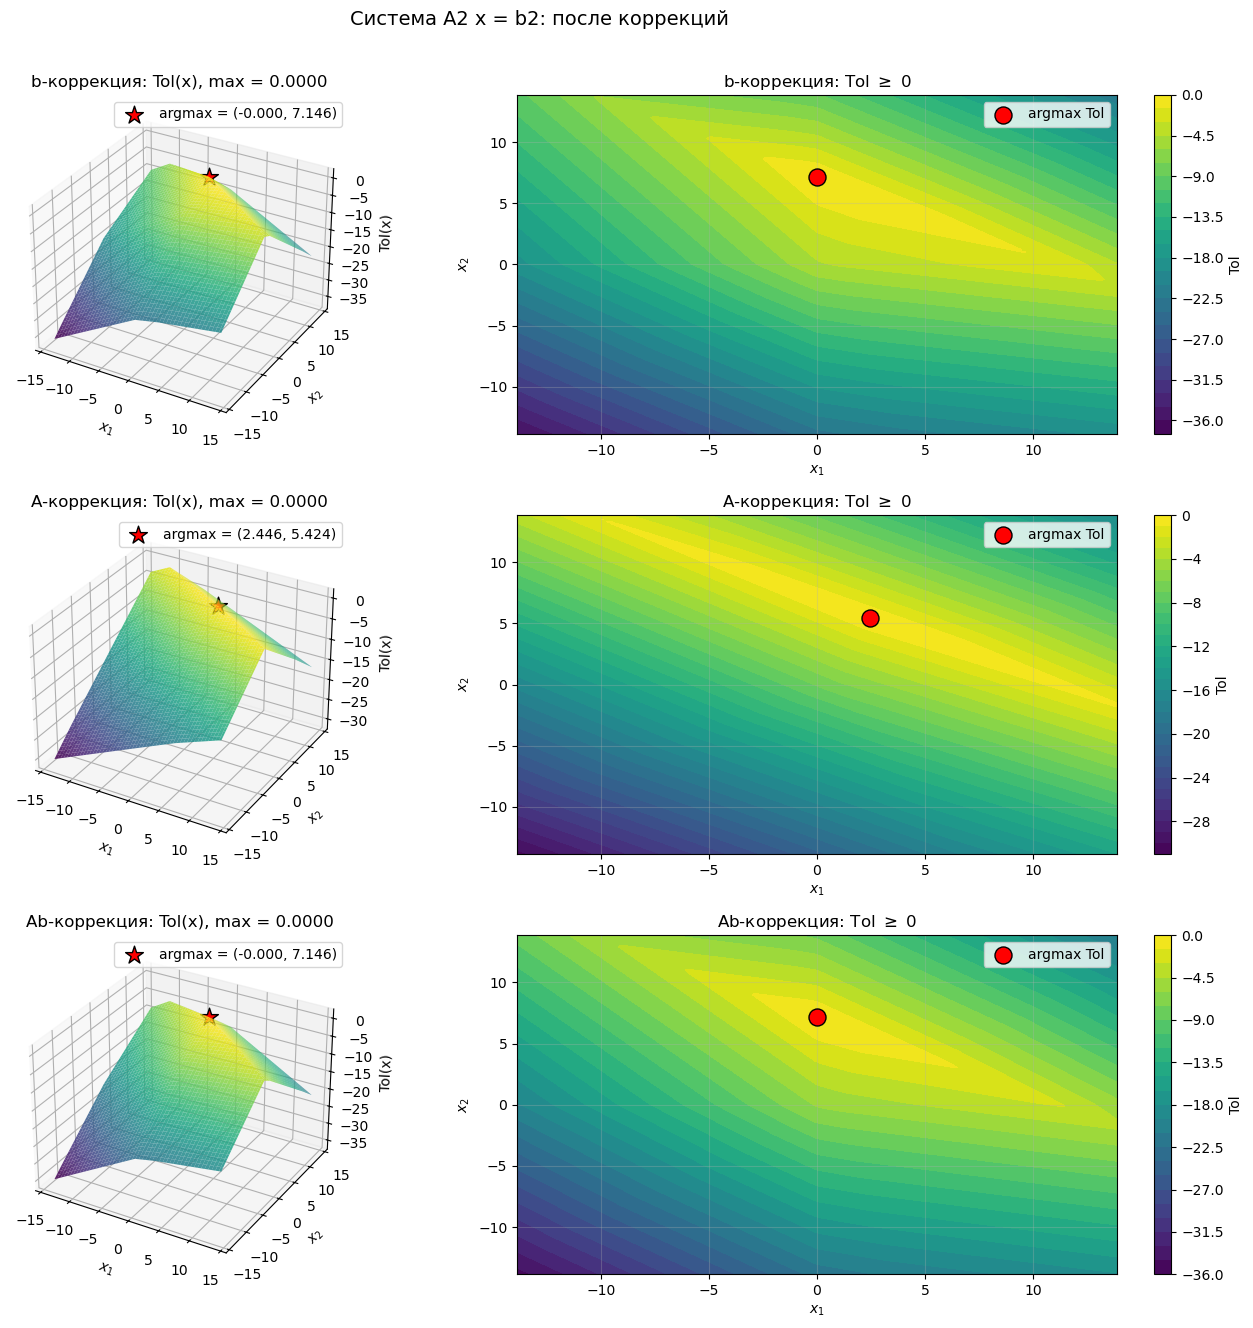


A3 x = b3
исходная: T = -2.290351, tau = (2.1404, 5.6871)
Tol_i(tau) = [-2.233918 -2.290351 -2.290351 -2.290351]
b: T' = 0.000000, tau' = (2.1404, 5.6871)
A: T' = 0.000000, tau' = (2.4464, 5.4241)
Ab: T' = 0.000000, tau' = (2.1404, 5.6871)


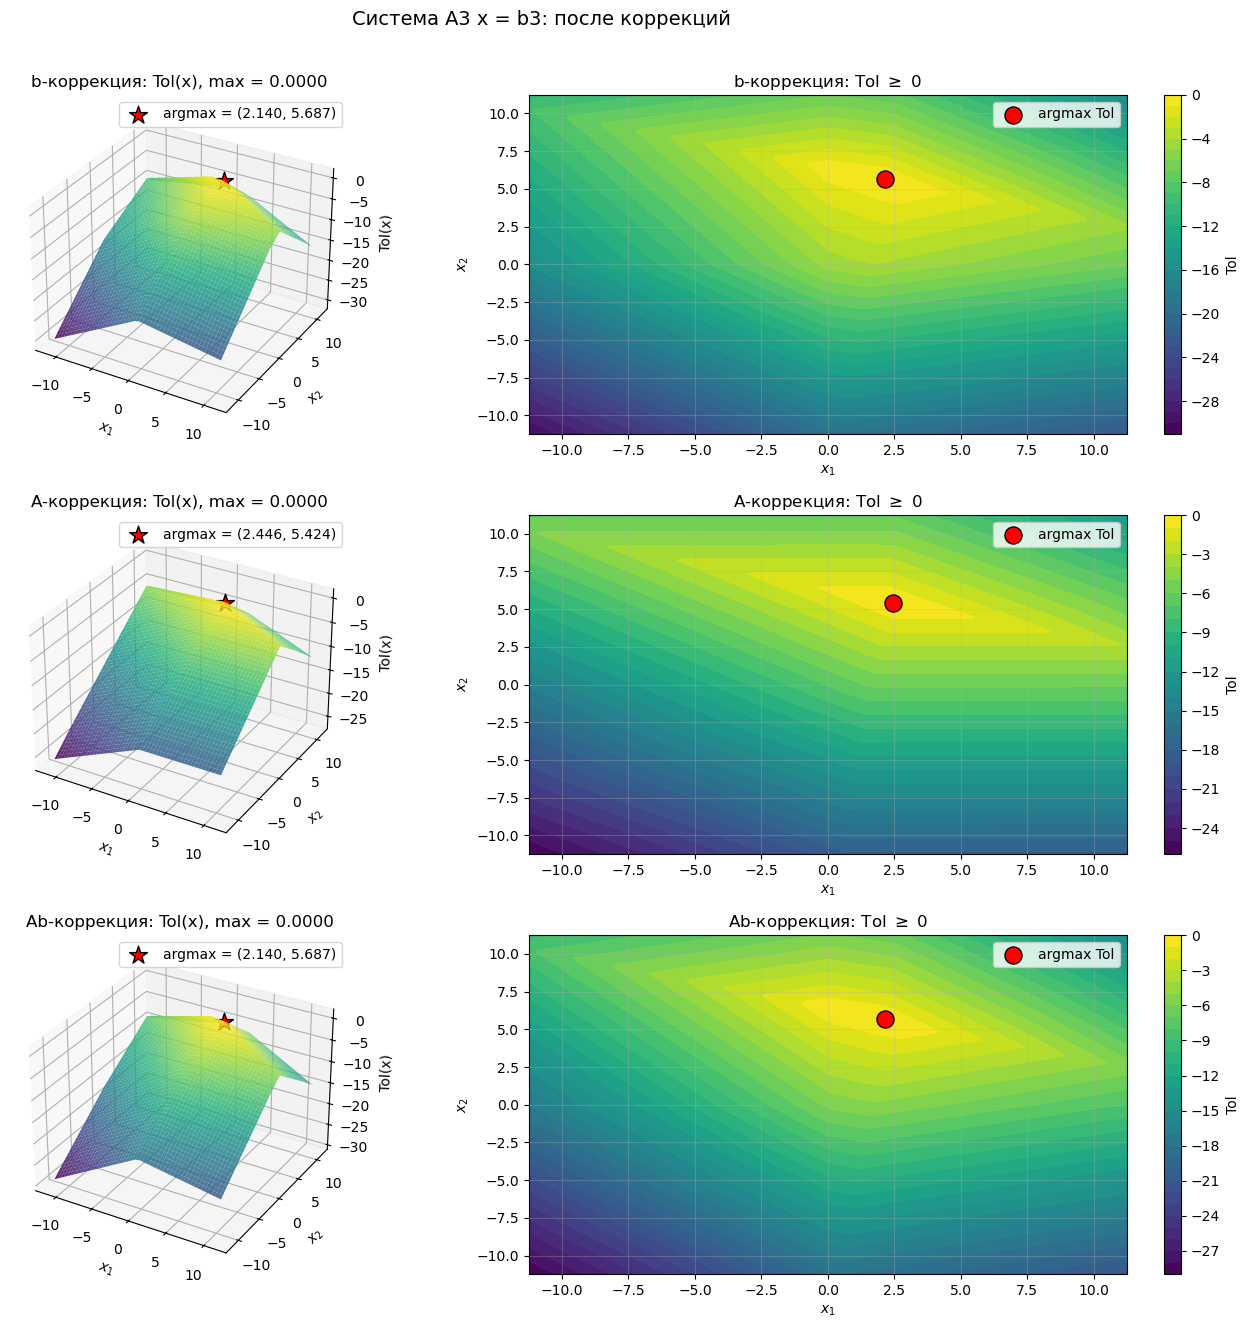


СВОДНАЯ ТАБЛИЦА
Система      Коррекция           T      tau_1      tau_2
--------------------------------------------------------------------------------
A1 x = b1    исходная    -1.898515    -0.0000     6.9307
A1 x = b1    b            0.000000    -0.0000     6.9307
A1 x = b1    A            0.000000    -0.0000     6.9307
A1 x = b1    Ab           0.000000    -0.0000     6.9307
A2 x = b2    исходная    -2.183333    -0.0000     7.1465
A2 x = b2    b            0.000000    -0.0000     7.1465
A2 x = b2    A            0.000000     2.4464     5.4241
A2 x = b2    Ab           0.000000    -0.0000     7.1465
A3 x = b3    исходная    -2.290351     2.1404     5.6871
A3 x = b3    b            0.000000     2.1404     5.6871
A3 x = b3    A            0.000000     2.4464     5.4241
A3 x = b3    Ab           0.000000     2.1404     5.6871


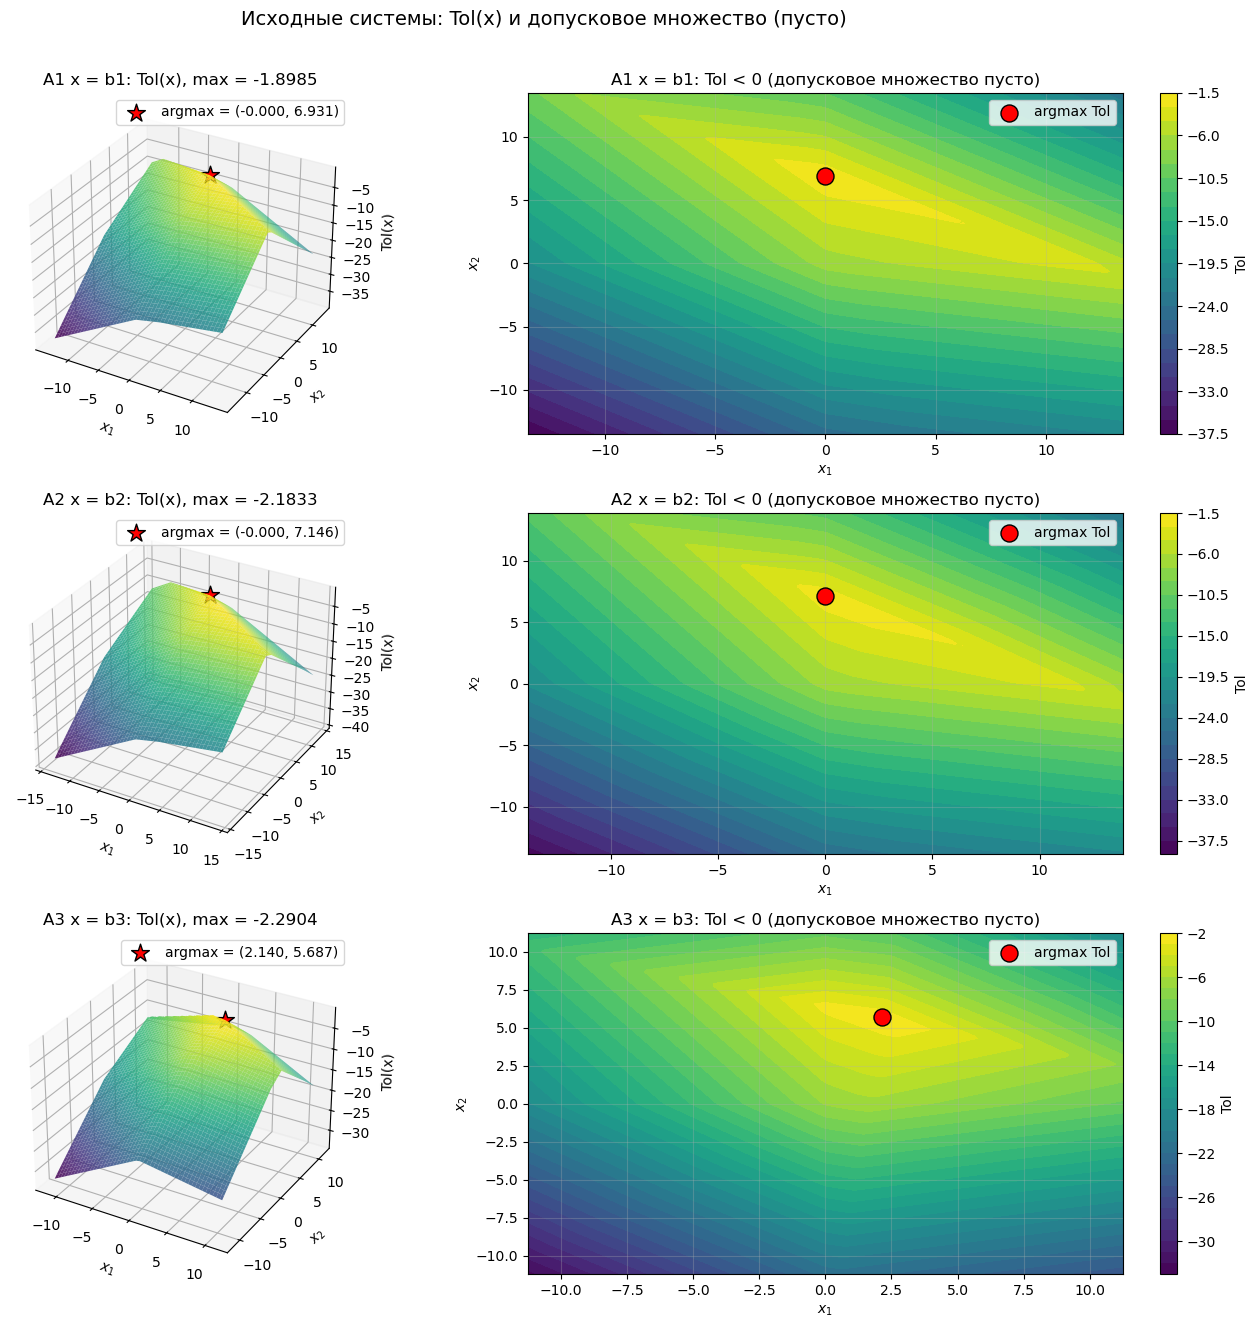

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

EPS = 1e-9

def iv(pairs):
    return np.array(pairs, dtype=float)

A1 = iv([[(0.25, 0.85), (0.70, 1.30)], [(0.35, 0.95), (0.76, 1.32)]])
b1 = iv([[(6.75, 7.15)], [(6.85, 7.25)]]).reshape(-1, 2)

A2 = iv([[(0.25, 0.85), (0.70, 1.30)], [(0.35, 0.95), (0.76, 1.32)], [(0.40, 1.00), (0.66, 1.26)]])
b2 = iv([[(6.75, 7.15)], [(6.85, 7.25)], [(6.90, 7.30)]]).reshape(-1, 2)

A3 = iv([[(0.25, 0.85), (0.70, 1.30)], [(0.35, 0.95), (0.76, 1.32)], [(0.40, 1.00), (0.66, 1.26)], [(-0.30, 0.30), (0.82, 1.38)]])
b3 = iv([[(6.75, 7.15)], [(6.85, 7.25)], [(6.90, 7.30)], [(5.80, 6.20)]]).reshape(-1, 2)

systems = [("A1 x = b1", A1, b1), ("A2 x = b2", A2, b2), ("A3 x = b3", A3, b3)]

def parts(A):
    return (A[..., 0] + A[..., 1]) / 2, (A[..., 1] - A[..., 0]) / 2

def parts_v(b):
    return (b[:, 0] + b[:, 1]) / 2, (b[:, 1] - b[:, 0]) / 2

def tol_rows(x, A, b):
    A_mid, A_rad = parts(A)
    b_mid, b_rad = parts_v(b)
    return b_rad - np.abs(b_mid - A_mid @ x) - A_rad @ np.abs(x)

def solve_tol_max(A, b):
    A_mid, A_rad = parts(A)
    b_mid, b_rad = parts_v(b)
    m, n = A_mid.shape
    ix, iy, iu = slice(0, n), slice(n, 2*n), slice(2*n, 2*n+m)
    it = 2*n + m
    nv = it + 1
    c = np.zeros(nv); c[it] = -1
    A_ub, b_ub = [], []
    for j in range(n):
        row = np.zeros(nv); row[j]=1; row[n+j]=-1; A_ub.append(row); b_ub.append(0)
        row = np.zeros(nv); row[j]=-1; row[n+j]=-1; A_ub.append(row); b_ub.append(0)
    for i in range(m):
        row = np.zeros(nv); row[ix]=-A_mid[i]; row[iu.start+i]=-1; A_ub.append(row); b_ub.append(-b_mid[i])
        row = np.zeros(nv); row[ix]=A_mid[i]; row[iu.start+i]=-1; A_ub.append(row); b_ub.append(b_mid[i])
    for i in range(m):
        row = np.zeros(nv); row[iy]=A_rad[i]; row[iu.start+i]=1; row[it]=1; A_ub.append(row); b_ub.append(b_rad[i])
    bounds = [(None,None)]*n + [(0,None)]*n + [(0,None)]*m + [(None,None)]
    res = linprog(c, A_ub=np.array(A_ub), b_ub=np.array(b_ub), bounds=bounds, method="highs")
    if not res.success:
        raise RuntimeError(res.message)
    tau = res.x[ix]
    T = float(res.x[it])
    if abs(T) < 1e-8: T = 0.0
    return {"tau": tau, "T": T, "row_scores": tol_rows(tau, A, b)}

def b_correction(A, b, T):
    K = max(0.0, -T)
    return A.copy(), b + np.array([[-K, K]] * b.shape[0])

def a_correction_lp(A, b, tau, T):
    A_mid, A_rad = parts(A)
    weights = np.abs(tau)
    c = np.ones(A_rad.size)
    A_ub = np.zeros((A_rad.shape[0], A_rad.size))
    b_ub = -np.maximum(0, -tol_rows(tau, A, b))
    for i in range(A_rad.shape[0]):
        A_ub[i, i*A_rad.shape[1]:(i+1)*A_rad.shape[1]] = -weights
    bounds = [(0.0, A_rad[i,j]) for i in range(A_rad.shape[0]) for j in range(A_rad.shape[1])]
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")
    if not res.success:
        raise RuntimeError(res.message)
    E = res.x.reshape(A_rad.shape)
    A_new = np.stack([A_mid - (A_rad - E), A_mid + (A_rad - E)], axis=-1)
    return A_new, b

def a_correction_bisection(A, b, max_iter=60):
    A_mid, A_rad = parts(A)
    def at(alpha):
        A_new = np.stack([A_mid - (1-alpha)*A_rad, A_mid + (1-alpha)*A_rad], axis=-1)
        return A_new, solve_tol_max(A_new, b)
    A0, r0 = at(0.0)
    if r0["T"] >= -EPS:
        return A0, b, r0
    A1, r1 = at(1.0)
    if r1["T"] < -EPS:
        return None, None, None
    lo, hi = 0.0, 1.0
    for _ in range(max_iter):
        mid = (lo + hi) / 2
        _, rm = at(mid)
        if rm["T"] >= -EPS: hi = mid
        else: lo = mid
    A_new, r_new = at(hi)
    return A_new, b, r_new

def a_correction(A, b, tau, T):
    try:
        A_new, b_new = a_correction_lp(A, b, tau, T)
        check = solve_tol_max(A_new, b_new)
        if check["T"] >= -1e-7:
            return A_new, b_new, check
    except RuntimeError:
        pass
    A_new, b_new, res = a_correction_bisection(A, b)
    if res is None:
        return None, None, None
    return A_new, b_new, res

def ab_correction(A, b, tau, T, alpha=0.5):
    A_mid, A_rad = parts(A)
    weights = np.abs(tau)
    needs = alpha * np.maximum(0, -tol_rows(tau, A, b))
    c = np.ones(A_rad.size)
    A_ub = np.zeros((A_rad.shape[0], A_rad.size))
    b_ub = -needs
    for i in range(A_rad.shape[0]):
        A_ub[i, i*A_rad.shape[1]:(i+1)*A_rad.shape[1]] = -weights
    bounds = [(0.0, A_rad[i,j]) for i in range(A_rad.shape[0]) for j in range(A_rad.shape[1])]
    try:
        res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")
        if res.success:
            E = res.x.reshape(A_rad.shape)
            A_new = np.stack([A_mid - (A_rad - E), A_mid + (A_rad - E)], axis=-1)
            rA = solve_tol_max(A_new, b)
            K_b = max(0.0, -rA["T"])
            b_new = b + np.array([[-K_b, K_b]] * b.shape[0])
            r_new = solve_tol_max(A_new, b_new)
            return A_new, b_new, r_new
    except RuntimeError:
        pass
    A_A, b_A, r_A = a_correction_bisection(A, b)
    if r_A is not None:
        K_b = max(0.0, -r_A["T"])
        b_new = b + np.array([[-K_b, K_b]] * b.shape[0])
        r_new = solve_tol_max(A_A, b_new)
        return A_A, b_new, r_new
    A_b, b_b = b_correction(A, b, T)
    return A_b, b_b, solve_tol_max(A_b, b_b)

# ============================================================
# Сборка больших фигур
# ============================================================
def make_big_figure(name, results_for_system, grid=150):
    taus = [r[4] for r in results_for_system]
    scale = max(1.0, max(np.max(np.abs(t)) for t in taus))
    ext = 1.8 * scale + 1.0
    xs = np.linspace(-ext, ext, grid)
    ys = np.linspace(-ext, ext, grid)
    X, Y = np.meshgrid(xs, ys)
    n_plots = len(results_for_system)
    fig = plt.figure(figsize=(15, 4.5 * n_plots))
    for row, (label, A, b, T, tau) in enumerate(results_for_system):
        A_mid, A_rad = parts(A)
        b_mid, b_rad = parts_v(b)
        Z = np.full_like(X, np.inf)
        for i in range(A_mid.shape[0]):
            rm = b_mid[i] - A_mid[i, 0] * X - A_mid[i, 1] * Y
            rp = A_rad[i, 0] * np.abs(X) + A_rad[i, 1] * np.abs(Y)
            Z = np.minimum(Z, b_rad[i] - np.abs(rm) - rp)
        ax1 = fig.add_subplot(n_plots, 2, 2 * row + 1, projection="3d")
        ax1.plot_surface(X, Y, Z, cmap="viridis", alpha=0.85)
        ax1.scatter([tau[0]], [tau[1]], [T], color="red", s=180, marker="*",
                    edgecolors="black", linewidths=1, zorder=5,
                    label=f"argmax = ({tau[0]:.3f}, {tau[1]:.3f})")
        ax1.set_xlabel("$x_1$"); ax1.set_ylabel("$x_2$"); ax1.set_zlabel("Tol(x)")
        ax1.set_title(f"{label}: Tol(x), max = {T:.4f}")
        ax1.legend(loc="upper right")
        ax2 = fig.add_subplot(n_plots, 2, 2 * row + 2)
        cs = ax2.contourf(X, Y, Z, levels=30, cmap="viridis")
        if Z.min() <= 0 <= Z.max():
            ax2.contour(X, Y, Z, levels=[0], colors="red", linewidths=2)
        ax2.scatter(tau[0], tau[1], color="red", s=150, marker="o",
                    edgecolor="black", zorder=5, label="argmax Tol")
        ax2.set_xlabel("$x_1$"); ax2.set_ylabel("$x_2$")
        ax2.set_title(f"{label}: Tol $\\geq$ 0")
        ax2.legend(loc="upper right"); ax2.grid(alpha=0.3)
        plt.colorbar(cs, ax=ax2, label="Tol")
    fig.suptitle(f"Система {name}: после коррекций", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

# ============================================================
# Основной прогон
# ============================================================
results_summary = []
for name, A, b in systems:
    print(f"\n{'='*60}\n{name}\n{'='*60}")
    analysis = solve_tol_max(A, b)
    T, tau = analysis["T"], analysis["tau"]
    print(f"исходная: T = {T:.6f}, tau = ({tau[0]:.4f}, {tau[1]:.4f})")
    print(f"Tol_i(tau) = {np.round(analysis['row_scores'], 6)}")
    results_summary.append((name, "исходная", T, tau, analysis["row_scores"]))
    if T >= -EPS:
        continue
    A_b, b_b = b_correction(A, b, T)
    r_b = solve_tol_max(A_b, b_b)
    print(f"b: T' = {r_b['T']:.6f}, tau' = ({r_b['tau'][0]:.4f}, {r_b['tau'][1]:.4f})")
    results_summary.append((name, "b", r_b["T"], r_b["tau"], r_b["row_scores"]))

    A_A, b_A, r_A = a_correction(A, b, tau, T)
    if r_A is not None:
        print(f"A: T' = {r_A['T']:.6f}, tau' = ({r_A['tau'][0]:.4f}, {r_A['tau'][1]:.4f})")
        results_summary.append((name, "A", r_A["T"], r_A["tau"], r_A["row_scores"]))

    A_Ab, b_Ab, r_Ab = ab_correction(A, b, tau, T)
    print(f"Ab: T' = {r_Ab['T']:.6f}, tau' = ({r_Ab['tau'][0]:.4f}, {r_Ab['tau'][1]:.4f})")
    results_summary.append((name, "Ab", r_Ab["T"], r_Ab["tau"], r_Ab["row_scores"]))

    results_for_system = [
        ("b-коррекция",  A_b,  b_b,  r_b["T"],  r_b["tau"]),
        ("A-коррекция",  A_A,  b_A,  r_A["T"],  r_A["tau"]),
        ("Ab-коррекция", A_Ab, b_Ab, r_Ab["T"], r_Ab["tau"]),
    ]
    make_big_figure(name, results_for_system)

print("\n" + "="*80)
print("СВОДНАЯ ТАБЛИЦА")
print("="*80)
print(f"{'Система':<12} {'Коррекция':<10} {'T':>10} {'tau_1':>10} {'tau_2':>10}")
print("-"*80)
for name, stage, T, tau, _ in results_summary:
    print(f"{name:<12} {stage:<10} {T:>10.6f} {tau[0]:>10.4f} {tau[1]:>10.4f}")

def make_original_figure(systems, grid=150):
    fig = plt.figure(figsize=(15, 4.5 * len(systems)))
    for row, (name, A, b) in enumerate(systems):
        analysis = solve_tol_max(A, b)
        T, tau = analysis["T"], analysis["tau"]

        A_mid, A_rad = parts(A)
        b_mid, b_rad = parts_v(b)
        scale = max(1.0, np.max(np.abs(tau)))
        ext = 1.8 * scale + 1.0
        xs = np.linspace(-ext, ext, grid)
        ys = np.linspace(-ext, ext, grid)
        X, Y = np.meshgrid(xs, ys)
        Z = np.full_like(X, np.inf)
        for i in range(A_mid.shape[0]):
            rm = b_mid[i] - A_mid[i, 0] * X - A_mid[i, 1] * Y
            rp = A_rad[i, 0] * np.abs(X) + A_rad[i, 1] * np.abs(Y)
            Z = np.minimum(Z, b_rad[i] - np.abs(rm) - rp)

        ax1 = fig.add_subplot(len(systems), 2, 2 * row + 1, projection="3d")
        ax1.plot_surface(X, Y, Z, cmap="viridis", alpha=0.85)
        ax1.scatter([tau[0]], [tau[1]], [T], color="red", s=180, marker="*",
                    edgecolors="black", linewidths=1, zorder=5,
                    label=f"argmax = ({tau[0]:.3f}, {tau[1]:.3f})")
        ax1.set_xlabel("$x_1$"); ax1.set_ylabel("$x_2$"); ax1.set_zlabel("Tol(x)")
        ax1.set_title(f"{name}: Tol(x), max = {T:.4f}")
        ax1.legend(loc="upper right")

        ax2 = fig.add_subplot(len(systems), 2, 2 * row + 2)
        cs = ax2.contourf(X, Y, Z, levels=30, cmap="viridis")
        ax2.scatter(tau[0], tau[1], color="red", s=150, marker="o",
                    edgecolor="black", zorder=5, label="argmax Tol")
        ax2.set_xlabel("$x_1$"); ax2.set_ylabel("$x_2$")
        ax2.set_title(f"{name}: Tol < 0 (допусковое множество пусто)")
        ax2.legend(loc="upper right"); ax2.grid(alpha=0.3)
        plt.colorbar(cs, ax=ax2, label="Tol")

    fig.suptitle("Исходные системы: Tol(x) и допусковое множество (пусто)", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

make_original_figure(systems)

In [9]:

print("\n" + "="*80)
print("РАВНОМЕРНАЯ A-КОРРЕКЦИЯ (сравнение с LP)")
print("="*80)

for name, A, b in systems:
    analysis = solve_tol_max(A, b)
    T, tau = analysis["T"], analysis["tau"]
    
    if T >= -EPS:
        continue
        
    # Формула: e = -T / (|tau_1| + |tau_2|)
    s = np.abs(tau).sum()
    e_uniform = -T / s

    A_mid, A_rad = parts(A)
    A_rad_new = np.maximum(0, A_rad - e_uniform)
    A_uniform = np.stack([A_mid - A_rad_new, A_mid + A_rad_new], axis=-1)

    r_uniform = solve_tol_max(A_uniform, b)

    sum_e_uniform = np.sum(A_rad - A_rad_new)

    A_LP, b_LP, r_LP = a_correction(A, b, tau, T)
    if r_LP is not None:
        A_mid_LP, A_rad_LP = parts(A_LP)
        sum_e_LP = np.sum(A_rad - A_rad_LP)
    else:
        sum_e_LP = np.nan
        
    print(f"\n{name}:")
    print(f"  T = {T:.6f}, tau = ({tau[0]:.4f}, {tau[1]:.4f}), s = {s:.4f}")
    print(f"  Равномерная: e = {e_uniform:.6f}, T' = {r_uniform['T']:.6f}, сумма сужений = {sum_e_uniform:.4f}")
    print(f"  LP (неравномерная):             T' = {r_LP['T']:.6f}, сумма сужений = {sum_e_LP:.4f}")


РАВНОМЕРНАЯ A-КОРРЕКЦИЯ (сравнение с LP)

A1 x = b1:
  T = -1.898515, tau = (-0.0000, 6.9307), s = 6.9307
  Равномерная: e = 0.273929, T' = 0.001096, сумма сужений = 1.0957
  LP (неравномерная):             T' = 0.000000, сумма сужений = 0.5479

A2 x = b2:
  T = -2.183333, tau = (-0.0000, 7.1465), s = 7.1465
  Равномерная: e = 0.305512, T' = 0.019209, сумма сужений = 1.7800
  LP (неравномерная):             T' = 0.000000, сумма сужений = 1.7652

A3 x = b3:
  T = -2.290351, tau = (2.1404, 5.6871), s = 7.8275
  Равномерная: e = 0.292604, T' = -0.019608, сумма сужений = 2.3156
  LP (неравномерная):             T' = 0.000000, сумма сужений = 2.3404
